In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    roc_curve,
    precision_recall_curve,
    auc
)

from imblearn.over_sampling import SMOTE

In [2]:
df = pd.read_csv('/content/creditcard.csv')
df.head()







,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,0,-1.359807,-0.072781,2.536347,1.378155,-0.338321,0.462388,0.239599,0.098698,0.363787,...,-0.018307,0.277838,-0.110474,0.066928,0.128539,-0.189115,0.133558,-0.021053,149.62,0.0
1,0,1.191857,0.266151,0.166480,0.448154,0.060018,-0.082361,-0.078803,0.085102,-0.255425,...,-0.225775,-0.638672,0.101288,-0.339846,0.167170,0.125895,-0.008983,0.014724,2.69,0.0
2,1,-1.358354,-1.340163,1.773209,0.379780,-0.503198,1.800499,0.791461,0.247676,-1.514654,...,0.247998,0.771679,0.909412,-0.689281,-0.327642,-0.139097,-0.055353,-0.059752,378.66,0.0
3,1,-0.966272,-0.185226,1.792993,-0.863291,-0.010309,1.247203,0.237609,0.377436,-1.387024,...,-0.108300,0.005274,-0.190321,-1.175575,0.647376,-0.221929,0.062723,0.061458,123.50,0.0
4,2,-1.158233,0.877737,1.548718,0.403034,-0.407193,0.095921,0.592941,-0.270533,0.817739,...,-0.009431,0.798278,-0.137458,0.141267,-0.206010,0.502292,0.219422,0.215153,69.99,0.0


In [3]:
print(df.shape)

(21878, 31)


In [4]:
print(df.info())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 21878 entries, 0 to 21877
Data columns (total 31 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   Time    21878 non-null  int64  
 1   V1      21878 non-null  float64
 2   V2      21878 non-null  float64
 3   V3      21878 non-null  float64
 4   V4      21878 non-null  float64
 5   V5      21878 non-null  float64
 6   V6      21878 non-null  float64
 7   V7      21878 non-null  float64
 8   V8      21878 non-null  float64
 9   V9      21878 non-null  float64
 10  V10     21878 non-null  float64
 11  V11     21878 non-null  float64
 12  V12     21878 non-null  float64
 13  V13     21878 non-null  float64
 14  V14     21878 non-null  float64
 15  V15     21878 non-null  float64
 16  V16     21878 non-null  float64
 17  V17     21878 non-null  float64
 18  V18     21878 non-null  float64
 19  V19     21878 non-null  float64
 20  V20     21878 non-null  float64
 21  V21     21878 non-null  float64
 22

In [5]:
print(df.isnull().sum())

Time      0
V1        0
V2        0
V3        0
V4        0
V5        0
V6        0
V7        0
V8        0
V9        0
V10       0
V11       0
V12       0
V13       0
V14       0
V15       0
V16       0
V17       0
V18       0
V19       0
V20       0
V21       0
V22       0
V23       0
V24       0
V25       0
V26       0
V27       0
V28       0
Amount    1
Class     1
dtype: int64


CLEANING

In [6]:
print("Duplicates:", df.duplicated().sum())

df.drop_duplicates(inplace=True)

df.reset_index(drop=True, inplace=True)

print(df.shape)

Duplicates: 81
(21797, 31)


In [7]:
print(df.isnull().sum().sum())

2


In [8]:
df.fillna(df.median(numeric_only=True), inplace=True)

In [9]:
print(df.isnull().sum().sum())

0


EDA

In [10]:
df['Class'].value_counts()

,count
Class,
0.0,21711
1.0,86


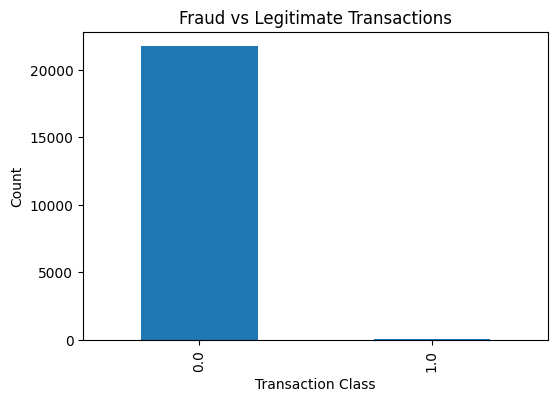

In [11]:
df['Class'].value_counts().plot(
    kind='bar',
    figsize=(6,4)
)

plt.title("Fraud vs Legitimate Transactions")
plt.xlabel("Transaction Class")
plt.ylabel("Count")

plt.show()

FRAUD PERCENTAGE

In [12]:
print(df['Class'].value_counts(normalize=True) * 100)

Class
0.0    99.60545
1.0     0.39455
Name: proportion, dtype: float64


In [13]:
x = df.drop('Class', axis=1)

y = df['Class']

In [14]:
xtrain,xtest,ytrain,ytest= train_test_split(
    x, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

FEATURE SACLING(V1–V28 columns are already transformed features)

In [15]:
sc = StandardScaler()

xtrain[['Time','Amount']] = sc.fit_transform(
    xtrain[['Time','Amount']]
)

xtest[['Time','Amount']] = sc.transform(
    xtest[['Time','Amount']]
)

BALANCING

In [16]:
sm = SMOTE(random_state=42)

xtrain1,ytrain1 = sm.fit_resample(
    xtrain,
    ytrain
)

In [17]:
ytrain.value_counts()
ytrain1.value_counts()

,count
Class,
0.0,17368
1.0,17368


BUILDING MODEL

In [18]:
lr = LogisticRegression(max_iter=1000)
lr.fit(xtrain1,ytrain1)
ypred = lr.predict(xtest)

In [19]:
classification_report(ytest,ypred)

'              precision    recall  f1-score   support\n\n         0.0       1.00      0.99      0.99      4343\n         1.0       0.21      0.88      0.34        17\n\n    accuracy                           0.99      4360\n   macro avg       0.61      0.93      0.67      4360\nweighted avg       1.00      0.99      0.99      4360\n'

In [20]:
rf = RandomForestClassifier(
    n_estimators=100,
    random_state=42,
    n_jobs=-1
)

rf.fit(xtrain1,ytrain1)

ypred_rf = rf.predict(xtest)

In [21]:
classification_report(ytest,ypred_rf)

'              precision    recall  f1-score   support\n\n         0.0       1.00      1.00      1.00      4343\n         1.0       0.88      0.88      0.88        17\n\n    accuracy                           1.00      4360\n   macro avg       0.94      0.94      0.94      4360\nweighted avg       1.00      1.00      1.00      4360\n'

COMPARING MODELS

In [23]:
models = {
    "Logistic Regression": lr,
    "Random Forest": rf
}

for name, model in models.items():

    y_pred = model.predict(xtest)

    print("\n", name)

    print("Precision:",
          precision_score(ytest,y_pred))

    print("Recall:",
          recall_score(ytest,y_pred))

    print("F1 Score:",
          f1_score(ytest,y_pred))

    print("ROC-AUC:",
          roc_auc_score(
              ytest,
              model.predict_proba(xtest)[:,1]
          ))


 Logistic Regression
Precision: 0.21428571428571427
Recall: 0.8823529411764706
F1 Score: 0.3448275862068966
ROC-AUC: 0.9915753545258766

 Random Forest
Precision: 0.8823529411764706
Recall: 0.8823529411764706
F1 Score: 0.8823529411764706
ROC-AUC: 0.9980834608768675


CONFUSION MATRIX

[[4341    2]
 [   2   15]]


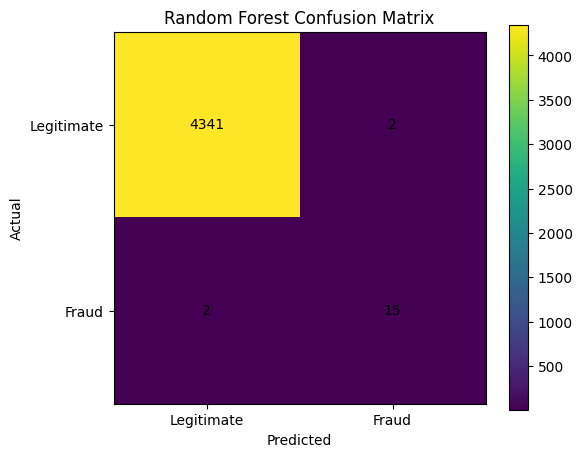

In [25]:
cm = confusion_matrix(ytest,ypred_rf)

print(cm)

plt.figure(figsize=(6,5))

plt.imshow(cm)

plt.title("Random Forest Confusion Matrix")

plt.xlabel("Predicted")

plt.ylabel("Actual")

plt.colorbar()

plt.xticks([0,1], ['Legitimate','Fraud'])
plt.yticks([0,1], ['Legitimate','Fraud'])

for i in range(2):
    for j in range(2):
        plt.text(j, i, cm[i,j],
                 ha='center',
                 va='center')

plt.show()

ROC CURVE

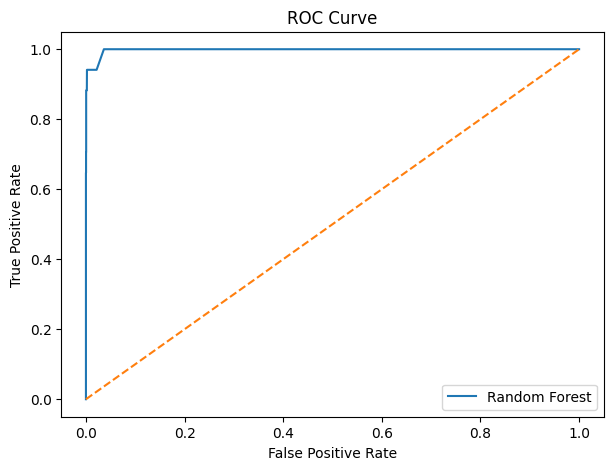

In [26]:
y_prob = rf.predict_proba(xtest)[:,1]

fpr, tpr, thresholds = roc_curve(ytest, y_prob)

plt.figure(figsize=(7,5))

plt.plot(fpr, tpr, label='Random Forest')

plt.plot([0,1], [0,1], linestyle='--')

plt.xlabel("False Positive Rate")

plt.ylabel("True Positive Rate")

plt.title("ROC Curve")

plt.legend()

plt.show()

PRECISION RECALL CURVE

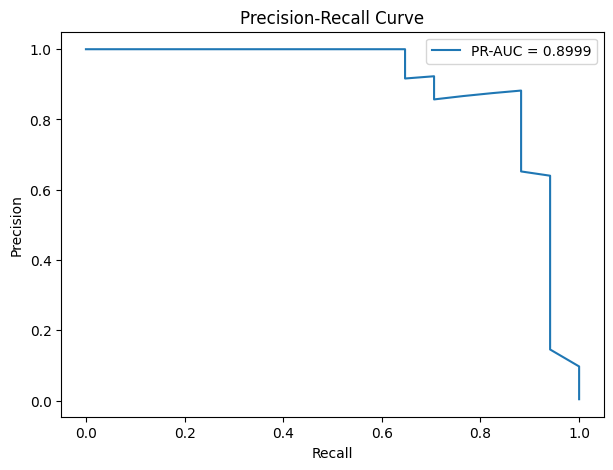

In [27]:
precision, recall, thresholds = precision_recall_curve(
    ytest,
    y_prob
)

pr_auc = auc(recall, precision)

plt.figure(figsize=(7,5))

plt.plot(recall, precision,
         label=f'PR-AUC = {pr_auc:.4f}')

plt.xlabel("Recall")

plt.ylabel("Precision")

plt.title("Precision-Recall Curve")

plt.legend()

plt.show()